# CNC Guard — 2. Fasea: Aurreprozesatzea eta Entrenamendua

**AABD Espezializazioa · 5071, 5072, 5073 moduluak**

Helburua: `ai4i2020_train.csv` datuetatik hutsegiteak iragarriko dituen eredu bat entrenatu eta `models/cnc_failure_model.pkl` gisa gorde.

## 1. Liburutegiak eta Karga

Beharrezko liburutegiak inportatu eta datuak kargatu.

In [10]:
# Liburutegiak inportatu
# ZURE KODEA HEMEN
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, precision_score, recall_score
from imblearn.over_sampling import SMOTE

In [4]:
# Datuak kargatu
# df = ...
# ZURE KODEA HEMEN
df = pd.read_csv('../data/ai4i2020_train.csv')

print(df)

     machine_id machine_type  air_temp_K  process_temp_K   rpm  torque_Nm  \
0       CNC-024            M       302.0           310.9  1456       47.2   
1       CNC-011            M       297.0           308.3  1399       46.4   
2       CNC-030            M       301.0           311.6  1357       45.6   
3       CNC-050            L       298.9           309.8  1411       56.3   
4       CNC-040            L       297.1           308.5  1733       28.7   
...         ...          ...         ...             ...   ...        ...   
7995    CNC-042            L       296.1           306.7  1409       42.8   
7996    CNC-043            L       302.7           311.1  1440       39.5   
7997    CNC-003            H       300.3           311.5  1464       41.0   
7998    CNC-042            L       301.7           311.2  1517       42.4   
7999    CNC-039            L       298.7           309.7  1462       46.8   

      tool_wear_min  machine_failure  failure_TWF  failure_HDF  failure_PWF

## 2. EDA — Datu-azterketa

Aztertu:
- Zutabe motak eta balioen barrutiak
- **Klase-banaketa**: zenbat hutsegite dute makinek? Zenbat dabiltza funtzionamendu egokian?
- Ezaugarrien arteko korrelazioa bilatu

> Galdera: klase-banaketa desorekatuak zein doiketa suposatzen d(it)u ereduan?

Zutabe motak
<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   machine_id       8000 non-null   str    
 1   machine_type     8000 non-null   str    
 2   air_temp_K       8000 non-null   float64
 3   process_temp_K   8000 non-null   float64
 4   rpm              8000 non-null   int64  
 5   torque_Nm        8000 non-null   float64
 6   tool_wear_min    8000 non-null   int64  
 7   machine_failure  8000 non-null   int64  
 8   failure_TWF      8000 non-null   int64  
 9   failure_HDF      8000 non-null   int64  
 10  failure_PWF      8000 non-null   int64  
 11  failure_OSF      8000 non-null   int64  
 12  failure_RNF      8000 non-null   int64  
dtypes: float64(3), int64(8), str(2)
memory usage: 812.6 KB

Balioen barrutiak
        air_temp_K  process_temp_K          rpm    torque_Nm  tool_wear_min  \
count  8000.000000     8000.000000  8000.00

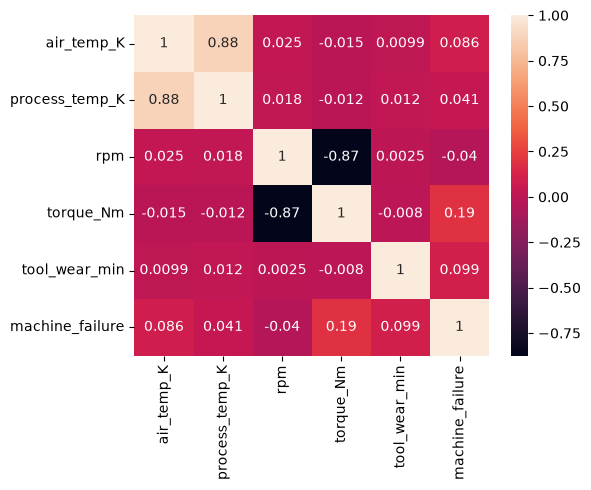

In [5]:
# EDA
# ZURE KODEA HEMEN
print("Zutabe motak")
df.info()

print("\nBalioen barrutiak")
# df.describe()
print(df.describe())

print("\nKlase banaketa")

print("FAIL / WORK")
fail = df[df['machine_failure'] > 0]
work = df[df['machine_failure'] <= 0]

print(f"{len(fail)} / {len(work)}")
print(f"% of fail: {df['machine_failure'].mean() * 100}")

print("\nKorrelazioak")
df_corr = df.loc[:, ~df.columns.str.startswith("failure_")]
print(df_corr.corr(numeric_only=True))

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(df_corr.corr(numeric_only=True), annot=True, ax=ax)
plt.tight_layout()
plt.show()

## 3. Aurreprozesatzea

Prestatu datuak entrenamendurako:
- Klase-desoreka tratatu (aukeratu ikuspegia eta **justifikatu**)
- (Aukerakoa) Feature engineering: ezaugarri artifizialak sortu,...

> Aukera posibleak?

In [6]:
# Preprocessing
# ZURE KODEA HEMEN
TYPE_MAP = {"L": 0, "M": 1, "H": 2}

df_fltr = df.loc[:, ~df.columns.str.startswith("failure_")].drop('machine_id', axis=1)
df_fltr['type_id'] = df_fltr['machine_type'].map(TYPE_MAP)
df_fltr = df_fltr.drop('machine_type', axis=1)
df_fltr['temp_diff'] = df_fltr['process_temp_K'] - df_fltr['air_temp_K']
df_fltr['power_est'] = df_fltr['torque_Nm'] * df_fltr['rpm'] * 2 * np.pi / 60 

assert df_fltr.isna().sum().sum() == 0, "Hay NaN: ¿machine_type con valores inesperados?"
print("Features:", df_fltr.columns.drop('machine_failure').tolist())

print(df_fltr.groupby("machine_failure")[["temp_diff", "power_est"]]
        .agg(["min", "median", "max"]).round(1))
print(df_fltr.groupby("type_id")["machine_failure"].agg(["count", "mean"]).round(4))

y_tmp = df_fltr['machine_failure']
print(y_tmp.value_counts())
print(f"Fallos: {y_tmp.mean()*100:.2f}% | proporción sin fallo/fallo: {(y_tmp == 0).sum() / (y_tmp == 1).sum():.1f} a 1")       

Features: ['air_temp_K', 'process_temp_K', 'rpm', 'torque_Nm', 'tool_wear_min', 'type_id', 'temp_diff', 'power_est']
                temp_diff              power_est                 
                      min median   max       min  median      max
machine_failure                                                  
0                     7.6    9.8  12.1    3515.0  6244.4   8998.0
1                     7.6    9.3  12.0    1148.4  7559.5  10469.9
         count    mean
type_id               
0         4830  0.0408
1         2381  0.0244
2          789  0.0203
machine_failure
0    7729
1     271
Name: count, dtype: int64
Fallos: 3.39% | proporción sin fallo/fallo: 28.5 a 1


**Klase desoreka tratatu**

*Opciones*:
- class_weight: hace que ambas clases tengan el mismo peso total aunque haya distinta cantidad, sin modificar los datos.
- SMOTE: crea fallos sintéticos por interpolación hasta igualar las clases, pero en variables categóricas como `type_id` puede generar valores sin sentido (por ejemplo, 0,37).
- Sobremuestreo aleatorio: duplica fallos existentes; favorece que el modelo memorice esas filas.
- Submuestreo: elimina filas de la clase mayoritaria; habría que descartar unas 7.400 filas y perder casi toda la información.
- Ajuste del umbral de decisión: no modifica lo que aprende el modelo, solo el punto de corte con el que una probabilidad se convierte en alerta.

*Elección*: class_weight="balanced" es la opción elegida para poder mantener coherencia en datos categóricos como type_id (el cual SMOTE puede generar un dato equivocado) y que ambas clases tengan el mismo peso total (siendo que 1 fallo tiene el peso equivalente a 28 no fallos), además que se mantienen los 8000 datos originales.

**Feature engineering**

- temp_diff: las temperaturas tienen una correlación de 0.876, este valor ayuda a medir el calentamiento real del proceso
- power_est: rpm y torque_Nm tienen una correlación negativa de −0,874 y su producto es la potencia en vatios.
- type_id: codifica L/M/H como 0/1/2, porque la tasa de fallo difiere por tipo (L 4,08%, M 2,44%, H 2,03%).

- Se decidió excluir las variables 'failure_*' ya que no tienen suficiente relevancia, a diferencia de machine_failure ya que este ayuda al modelo a comprobar directamente las condiciones para una falla general. También se excluyó machine_id ya que el identificador no tiene importancia en el entrenamiento del modelo.

## 4. Train / Validation Zatiketa

Garrantzitsua: `stratify=y` parametroa erabili klase-proportzioak mantentzeko.

In [7]:
# FEATURES aldagaia definitu — scoring-api-ak espero duen orden berdinean!
FEATURES = ['air_temp_K', 'process_temp_K', 'rpm', 'torque_Nm', 'tool_wear_min', 'temp_diff', 'power_est', 'type_id']

# Train/val zatitu
# ZURE KODEA HEMEN

X = df_fltr[FEATURES]
y = df_fltr['machine_failure']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

## 5. Entrenamendua

Eredu bat (gutxienez) entrenatu. Aukerakoa: hainbat eredu konparatu.

In [11]:
# Entrenamendua
# ZURE KODEA HEMEN
rf = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42, n_jobs=-1)

rf.fit(X_train, y_train)

clw_pred = rf.predict(X_test)
clw_prob = rf.predict_proba(X_test)[:, 1]

print("Class weight:")
print(f"Recall: {recall_score(y_test, clw_pred):.4f}")
print(f"Precision: {precision_score(y_test, clw_pred):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, clw_prob):.4f}")

rf_smote = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
X_smote, y_smote = SMOTE(random_state=42).fit_resample(X_train, y_train)
rf_smote.fit(X_smote, y_smote)

smt_pred = rf_smote.predict(X_test)
smt_prob = rf_smote.predict_proba(X_test)[:, 1]

print("\nSMOTE:")
print(f"Recall: {recall_score(y_test, smt_pred):.4f}")
print(f"Precision: {precision_score(y_test, smt_pred):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, smt_prob):.4f}")

Class weight:
Recall: 0.7407
Precision: 0.8696
ROC-AUC: 0.9720

SMOTE:
Recall: 0.7778
Precision: 0.6667
ROC-AUC: 0.9737


## 6. Ebaluazioa

Ebaluatu honako metrikekin:
- `classification_report` — precision, **recall**, f1-score
- `confusion_matrix` — bistaratu eta interpretatu
- `roc_auc_score`

> Zergatik da recall garrantzitsuagoa precision baino kasu honetan?

              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1546
           1       0.87      0.74      0.80        54

    accuracy                           0.99      1600
   macro avg       0.93      0.87      0.90      1600
weighted avg       0.99      0.99      0.99      1600



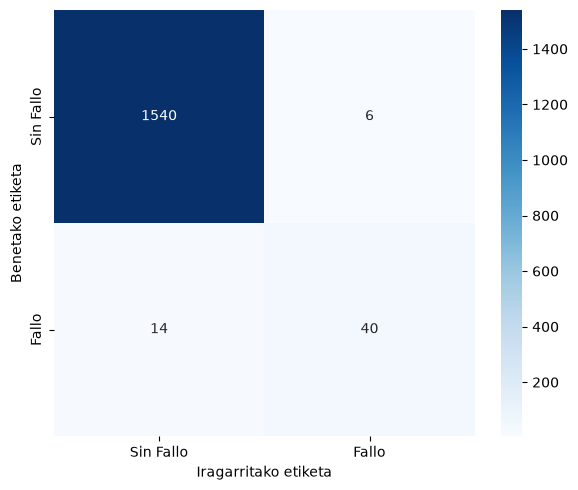

ROC-AUC score: 0.9720


In [12]:
# Ebaluazioa
# ZURE KODEA HEMEN

y_pred = rf.predict(X_test)
y_prob = rf.predict_proba(X_test)[:, 1]
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, ax=ax, fmt="d", cmap="Blues", xticklabels=["Sin Fallo", "Fallo"], yticklabels=["Sin Fallo", "Fallo"])
ax.set_ylabel("Benetako etiketa")
ax.set_xlabel("Iragarritako etiketa")
plt.tight_layout()
plt.show()

print(f'ROC-AUC score: {roc_auc_score(y_test, y_prob):.4f}')

## 6b. Atalasearen Doikuntza (Threshold Tuning)

Atalase lehenetsiak (0.5) Negatibo Faltsu (FN) gehiegi uzten baditu, saiatu atalasea jaisten (adib. 0.20 edo 0.15):
- Erabili predict_proba probabilitateak lortzeko.
- Marraztu Precision-Recall kurba (PrecisionRecallDisplay) atalase optimoa aukeratzeko.
- Aplikatu atalase berria eta atera berriro classification_report eta confusion_matrix.

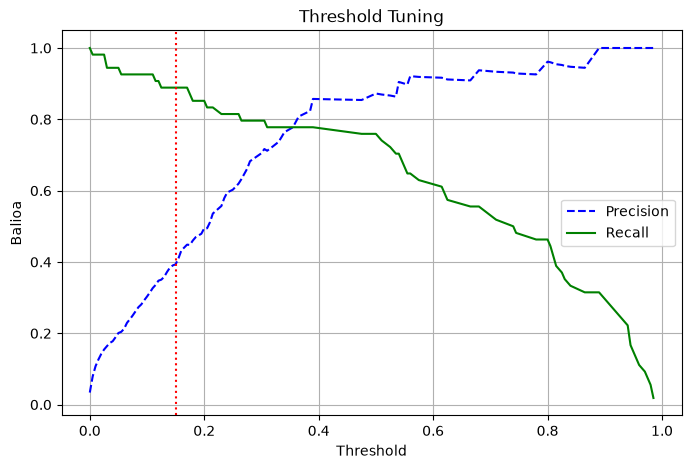

              precision    recall  f1-score   support

           0       1.00      0.95      0.97      1546
           1       0.39      0.89      0.55        54

    accuracy                           0.95      1600
   macro avg       0.69      0.92      0.76      1600
weighted avg       0.98      0.95      0.96      1600



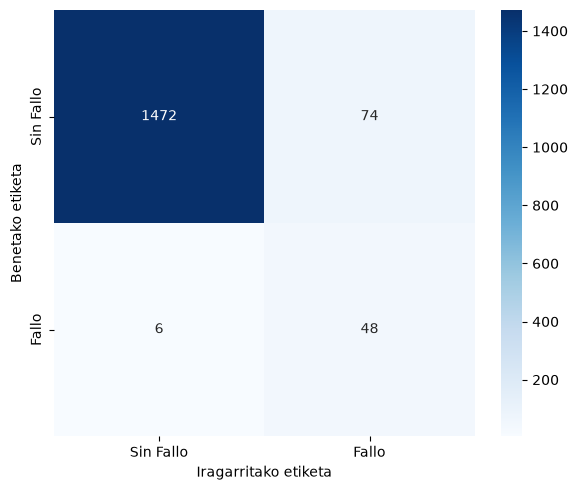

In [13]:
# Atalasearen Doikuntza (Threshold Tuning)
# y_prob = model.predict_proba(X_val)[:, 1]
from sklearn.metrics import precision_recall_curve
# ZURE KODEA HEMEN
y_prob = rf.predict_proba(X_test)[:, 1]
ATALASEA = 0.15

precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob)

plt.figure(figsize=(8,5))
plt.plot(thresholds, precisions[:-1], "--b", label="Precision")
plt.plot(thresholds, recalls[:-1], "g-", label="Recall")
plt.xlabel('Threshold')
plt.ylabel('Balioa')
plt.title("Threshold Tuning")
plt.legend(loc="best")
plt.grid(True)
plt.axvline(ATALASEA, color="red", ls=":")
plt.show()

y_iragarkia_doitua = (y_prob >= ATALASEA).astype(int)

print(classification_report(y_test, y_iragarkia_doitua))

cm = confusion_matrix(y_test, y_iragarkia_doitua)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, ax=ax, fmt="d", cmap="Blues", xticklabels=["Sin Fallo", "Fallo"], yticklabels=["Sin Fallo", "Fallo"])
ax.set_ylabel("Benetako etiketa")
ax.set_xlabel("Iragarritako etiketa")
plt.tight_layout()
plt.show()

## 7. Eredua Gorde

Scoring-api-k `/models/cnc_failure_model.pkl` bilatu behar du.

In [14]:
# joblib.dump(model, '../models/cnc_failure_model.pkl')
# ZURE KODEA HEMEN
joblib.dump(rf, '../models/cnc_failure_model.pkl')

# Egiaztatu scoring-api-k ondo kargatzen duela:
# docker compose restart scoring-api
# curl http://localhost:8000/health  → 'model_loaded: true' ikusi behar da

['../models/cnc_failure_model.pkl']